### Import Statments, load csv

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import skew

import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


json_fp = r"..\results\ocr_all_results.json"
image_dir = Path(r"..\sample_images")

csv_file = r"..\results\ocr_evaluation_detail.csv"

df = pd.read_csv(csv_file)

### Aggregate Summary Stats

In [2]:
df["Model"] = df["profile"].map({
    "baseline": "EasyOCR",
    "large": "Florence-2"
})


summary = (
    df.groupby("Model")
      .agg(
          Samples=("image", "count"),
          Mean_CER=("normalized_cer", "mean"),
          Median_CER=("normalized_cer", "median"),
          Exact_Match_Rate=("exact_match_normalized", "mean"),
          Mean_Runtime=("analysis_seconds", "mean"),
      )
      .reset_index()
)

print("\n=== OCR Model Summary ===\n")
print(summary)


=== OCR Model Summary ===

        Model  Samples  Mean_CER  Median_CER  Exact_Match_Rate  Mean_Runtime
0     EasyOCR      134  0.218036    0.076255          0.373134      0.899471
1  Florence-2      134  0.053673    0.000000          0.671642      8.902323


### Summary Statistics

In [3]:
print("\n=== OCR Model Summary Baseline ===\n")
print(df[df["profile"] == "baseline"]["normalized_cer"].describe())

print("\n=== OCR Model Summary Large  ===\n")
print(df[df["profile"] == "large"]["normalized_cer"].describe())


=== OCR Model Summary Baseline ===

count    134.000000
mean       0.218036
std        0.290358
min        0.000000
25%        0.000000
50%        0.076255
75%        0.393750
max        1.000000
Name: normalized_cer, dtype: float64

=== OCR Model Summary Large  ===

count    134.000000
mean       0.053673
std        0.137704
min        0.000000
25%        0.000000
50%        0.000000
75%        0.068992
max        1.375000
Name: normalized_cer, dtype: float64


In [4]:
def summary_stats(model):
    subset = df[df["Model"] == model]["normalized_cer"]
    print(f"\n=== {model} Normalized CER ===\n")
    print(subset.describe())

    print(f"Variance      : {subset.var():.6f}")
    print(f"Std Dev       : {subset.std():.6f}")
    print(f"Skewness      : {skew(subset):.4f}")
    print(f"IQR           : {subset.quantile(0.75) - subset.quantile(0.25):.6f}")

    print("\nPercentiles")
    print(subset.quantile([0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99]))

print(summary_stats("EasyOCR"))


=== EasyOCR Normalized CER ===

count    134.000000
mean       0.218036
std        0.290358
min        0.000000
25%        0.000000
50%        0.076255
75%        0.393750
max        1.000000
Name: normalized_cer, dtype: float64
Variance      : 0.084308
Std Dev       : 0.290358
Skewness      : 1.2610
IQR           : 0.393750

Percentiles
0.01    0.000000
0.05    0.000000
0.10    0.000000
0.25    0.000000
0.50    0.076255
0.75    0.393750
0.90    0.704529
0.95    0.833333
0.99    1.000000
Name: normalized_cer, dtype: float64
None


In [5]:
print(summary_stats("Florence-2"))


=== Florence-2 Normalized CER ===

count    134.000000
mean       0.053673
std        0.137704
min        0.000000
25%        0.000000
50%        0.000000
75%        0.068992
max        1.375000
Name: normalized_cer, dtype: float64
Variance      : 0.018962
Std Dev       : 0.137704
Skewness      : 6.9118
IQR           : 0.068992

Percentiles
0.01    0.000000
0.05    0.000000
0.10    0.000000
0.25    0.000000
0.50    0.000000
0.75    0.068992
0.90    0.159524
0.95    0.200000
0.99    0.333333
Name: normalized_cer, dtype: float64
None


### Summary Plots of Model Performace

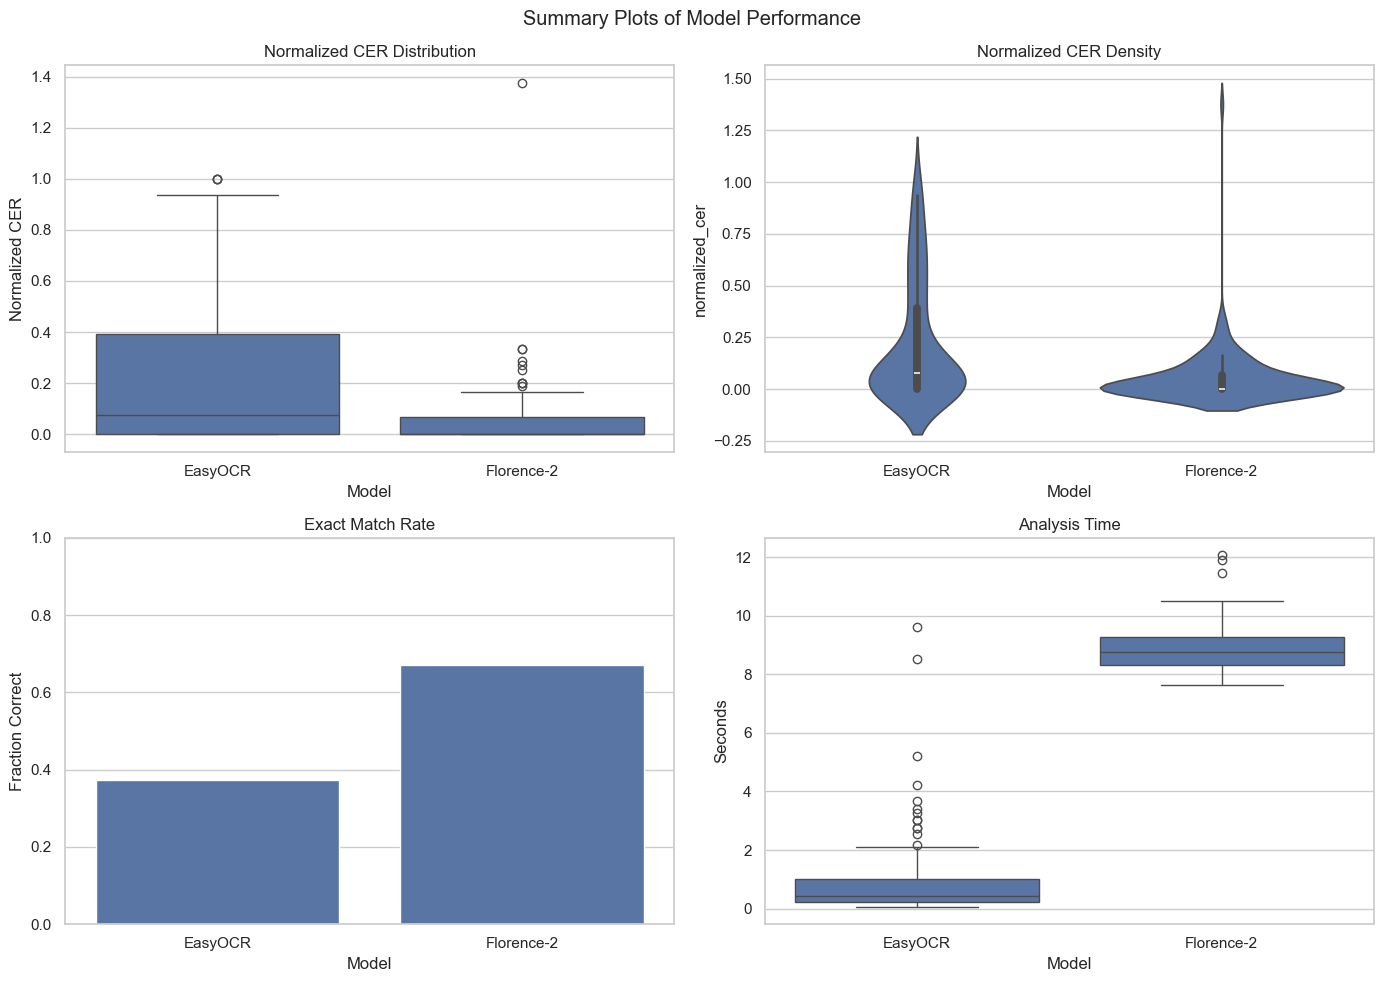

In [6]:

sns.set_theme(style="whitegrid", palette="deep")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle("Summary Plots of Model Performance")

sns.boxplot(
    data=df,
    x="Model",
    y="normalized_cer",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Normalized CER Distribution")
axes[0, 0].set_ylabel("Normalized CER")

sns.violinplot(
    data=df,
    x="Model",
    y="normalized_cer",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Normalized CER Density")

exact_match = (
    df.groupby("Model")["exact_match_normalized"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=exact_match,
    x="Model",
    y="exact_match_normalized",
    ax=axes[1, 0]
)

axes[1, 0].set_ylim(0, 1)
axes[1, 0].set_title("Exact Match Rate")
axes[1, 0].set_ylabel("Fraction Correct")

sns.boxplot(
    data=df,
    x="Model",
    y="analysis_seconds",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Analysis Time")
axes[1, 1].set_ylabel("Seconds")

plt.tight_layout()
plt.savefig(r".\images\ocr_model_comparison.png", dpi=300)
plt.show()

### Comparison of Stats Grouped by Category and Model


=== Category Performance ===

     category       Model  Mean_CER  Exact_Match
0     Engrave     EasyOCR  0.257541     0.323077
1     Engrave  Florence-2  0.065751     0.692308
2  Laser Mark     EasyOCR  0.180821     0.420290
3  Laser Mark  Florence-2  0.042296     0.652174


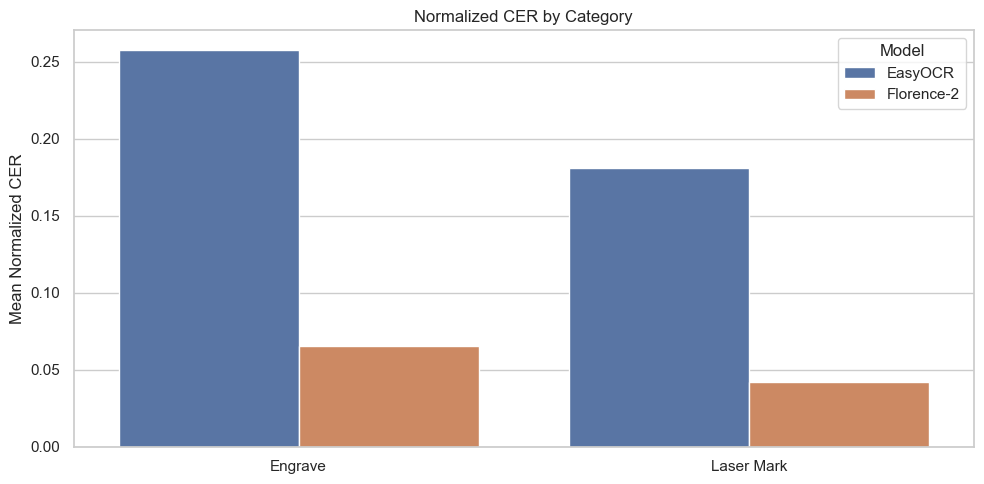

In [7]:

category_stats = (
    df.groupby(["category", "Model"])
      .agg(
          Mean_CER=("normalized_cer", "mean"),
          Exact_Match=("exact_match_normalized", "mean")
      )
      .reset_index()
)

print("\n=== Category Performance ===\n")
print(category_stats)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_stats,
    x="category",
    y="Mean_CER",
    hue="Model"
)

plt.title("Normalized CER by Category")
plt.ylabel("Mean Normalized CER")
plt.xlabel("")
plt.tight_layout()
plt.savefig(r".\images\ocr_category_cer.png", dpi=300)
plt.show()

### ECDF Plot

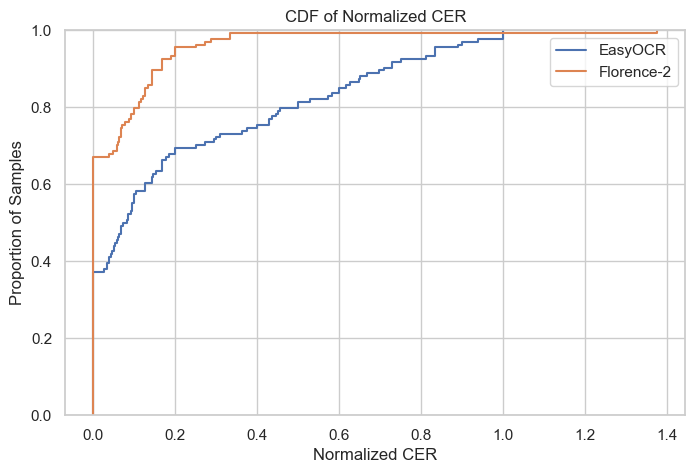

In [ ]:
plt.figure(figsize=(8,5))

for model in ["EasyOCR", "Florence-2"]:

    sns.ecdfplot(
        data=df[df["Model"] == model],
        x="normalized_cer",
        label=model
    )

plt.legend()
plt.title("CDF of Normalized CER")
plt.xlabel("Normalized CER")
plt.ylabel("Proportion of Samples")

plt.savefig(r".\images\ECDF.png", dpi=300)
plt.show()

Loaded 134 images
Loaded 268 OCR records

Processing: ocr_test_023
Detections: 2

Processing: ocr_test_025
Detections: 3

Processing: ocr_test_122
Detections: 0

Processing: ocr_test_033
Detections: 4


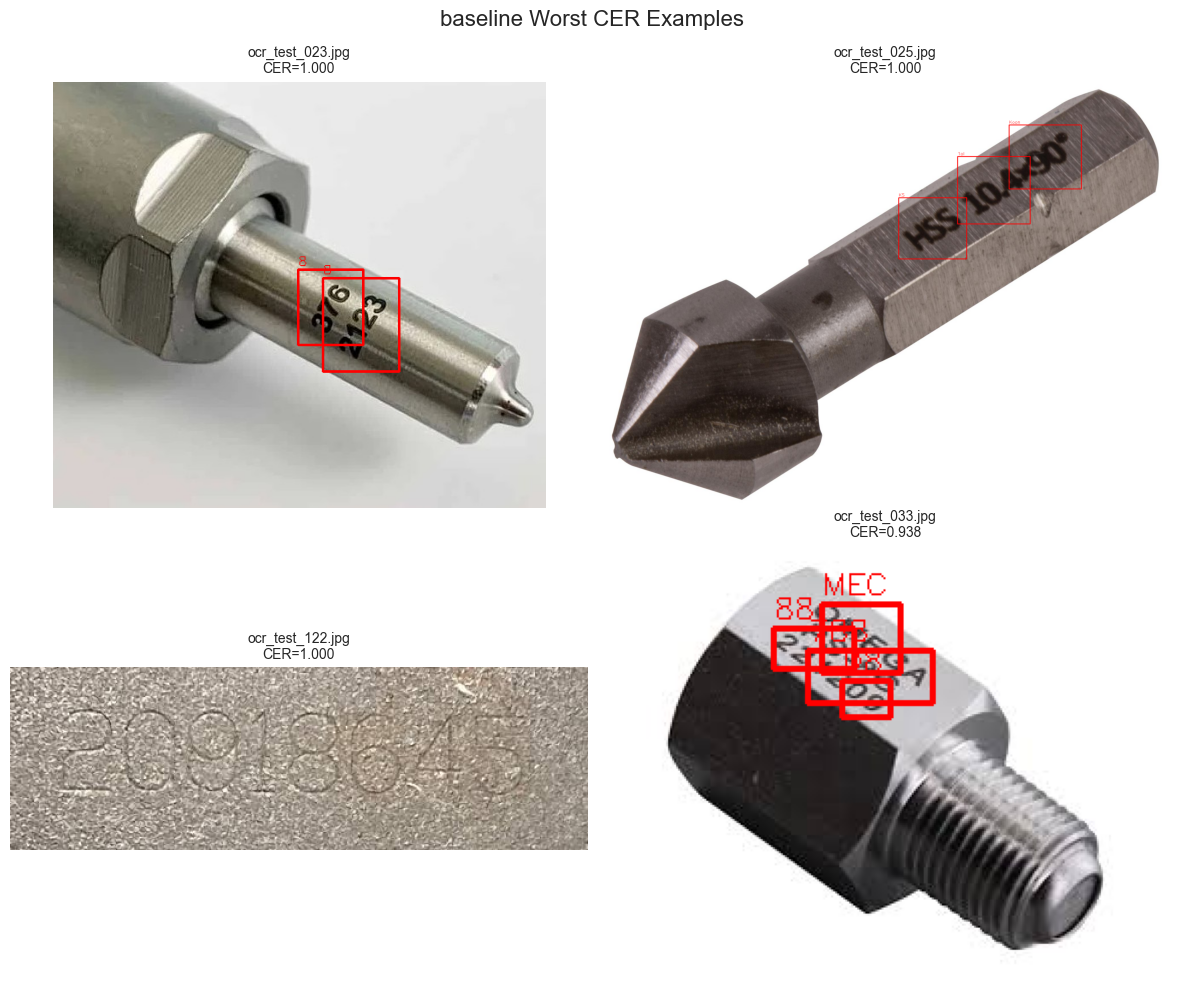


Processing: ocr_test_122
Detections: 1

Processing: ocr_test_065
Detections: 2

Processing: ocr_test_048
Detections: 1

Processing: ocr_test_034
Detections: 1


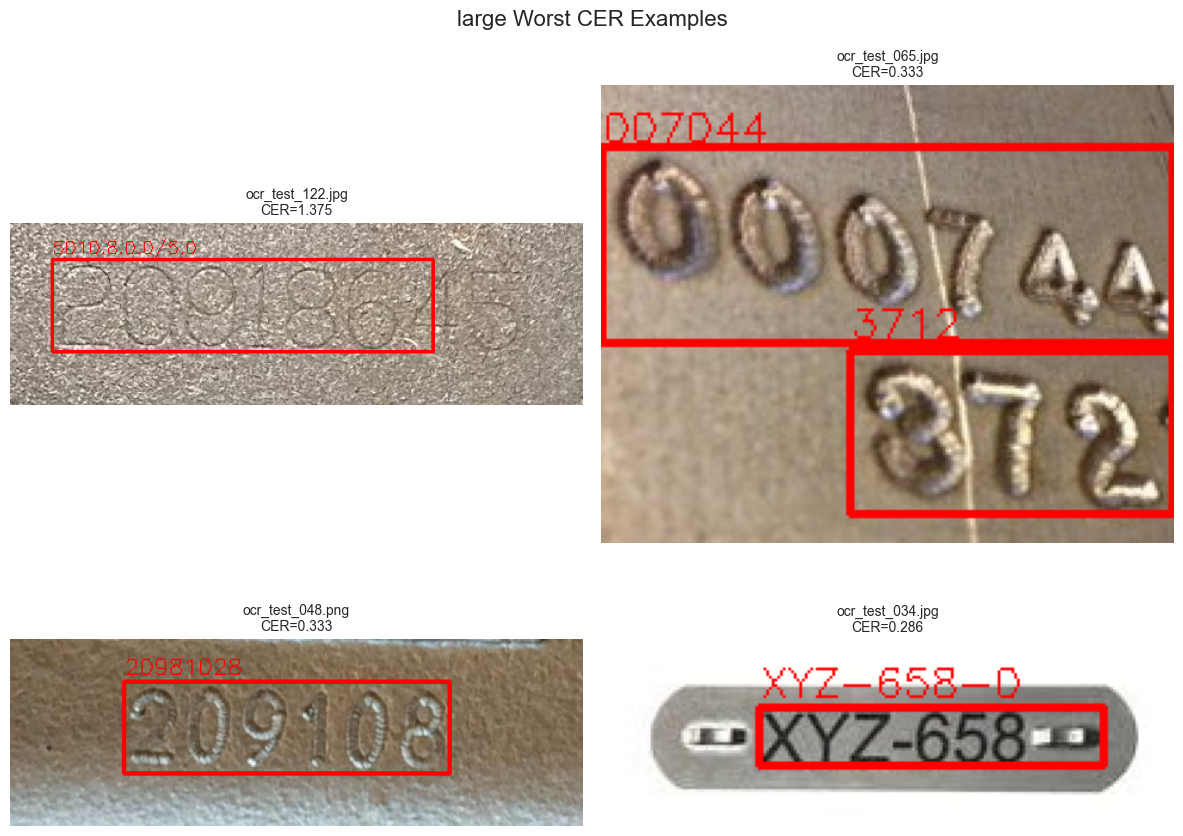

In [9]:

num_outliers = 4

with open(json_fp, "r", encoding="utf-8") as f:
    ocr_results = json.load(f)

image_lookup = {}

for path in image_dir.rglob("*"):

    if path.suffix.lower() in {
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".tif",
        ".tiff",
    }:

        image_lookup[path.stem.lower()] = path

print(f"Loaded {len(image_lookup)} images")


ocr_lookup = {}

for image_entry in ocr_results["images"]:

    image_stem = Path(
        image_entry["image"]
    ).stem.lower()

    for model in image_entry["models"]:

        key = (
            image_stem,
            model["profile"]
        )

        ocr_lookup[key] = model

print(f"Loaded {len(ocr_lookup)} OCR records")

def find_iqr_outliers(df_model):

    q1 = df_model["normalized_cer"].quantile(0.25)
    q3 = df_model["normalized_cer"].quantile(0.75)

    iqr = q3 - q1

    upper = q3 + (1.5 * iqr)

    return (
        df_model[
            df_model["normalized_cer"] > upper
        ]
        .copy()
        .sort_values(
            "normalized_cer",
            ascending=False
        )
    )

def draw_ocr_boxes(image,detections,draw_text=True,):

    output = image.copy()

    for det in detections:

        try:

            x1, y1, x2, y2 = det["box_xyxy"]

            cv2.rectangle(
                output,
                (int(x1), int(y1)),
                (int(x2), int(y2)),
                (255, 0, 0),
                2,
            )

            if draw_text:

                text = det.get(
                    "text",
                    ""
                )

                cv2.putText(
                    output,
                    text[:30],
                    (
                        int(x1),
                        max(
                            int(y1) - 5,
                            20
                        )
                    ),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255, 0, 0),
                    1,
                )

        except Exception as ex:

            print(
                f"Bad detection: {ex}"
            )

    return output

def create_failure_gallery(df_model,profile,n=4,):

    worst = (
        df_model
        .sort_values(
            "normalized_cer",
            ascending=False,
        )
        .head(n)
    )

    cols = 2
    rows = int(np.ceil(n / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, rows * 5)
    )

    axes = np.array(axes).flatten()

    for ax in axes:
        ax.axis("off")

    for idx, (_, row) in enumerate(
        worst.iterrows()
    ):

        image_stem = Path(
            str(row["image"])
        ).stem.lower()

        print(
            f"\nProcessing:"
            f" {image_stem}"
        )

        image_path = image_lookup.get(
            image_stem
        )

        if image_path is None:

            print(
                f"Image not found:"
                f" {image_stem}"
            )

            continue

        key = (
            image_stem,
            profile
        )

        model_data = ocr_lookup.get(
            key
        )

        if model_data is None:

            print(
                f"OCR result missing:"
                f" {key}"
            )

            continue

        img = cv2.imread(
            str(image_path)
        )

        if img is None:

            print(
                f"OpenCV failed:"
                f" {image_path}"
            )

            continue

        img = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )

        detections = (
            model_data
            .get("payload", {})
            .get("detections", [])
        )

        print(
            f"Detections:"
            f" {len(detections)}"
        )

        img = draw_ocr_boxes(
            img,
            detections,
            draw_text=True
        )

        ax = axes[idx]

        ax.imshow(img)

        ax.set_title(
            (
                f"{image_path.name}\n"
                f"CER={row['normalized_cer']:.3f}"
            ),
            fontsize=10
        )

        ax.axis("off")

    plt.suptitle(
        f"{profile} Worst CER Examples",
        fontsize=16,
    )

    plt.tight_layout()

    plt.savefig(
        rf".\images\{profile}_failure_gallery.png",
        dpi=300,
    )

    plt.show()

create_failure_gallery(
    df[df["profile"] == "baseline"],
    profile="baseline",
    n=num_outliers,
)

create_failure_gallery(
    df[df["profile"] == "large"],
    profile="large",
    n=num_outliers,
)
